# The Hatch C3 · Olist · Machine Learning Comercial

Resolvemos 3 misiones con modelos clásicos de ML. En cada una comparamos modelos,
detectamos overfitting/underfitting y sacamos conclusiones de negocio.

| # | Misión | Tipo de problema | Modelos |
| --- | --- | --- | --- |
| 1 | 🚚 Predicción de Entregas | Regresión | Árbol de decisión, Random Forest, Gradient Boosting |
| 2 | 🛍️ Recomendaciones Inteligentes | No supervisado | PCA + K-Means |
| 3 | 🧠 Análisis de Sentimientos | Clasificación de texto | Naive Bayes, SVM lineal, Regresión logística |

Todas las misiones siguen el mismo esqueleto:
**Datos → Features → Pipeline → Comparación (CV) → Overfitting → Visualización → Interpretación**

| Datos | Fuente |
| --- | --- |
| `data/olist_*.csv` | [Brazilian E-Commerce Public Dataset by Olist · Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) |

Los CSV se leen localmente desde `data/`, sin descargas.

### 0. Configuración

Cargamos las bibliotecas y las 7 tablas de Olist. Usamos semilla 42 en todo el
notebook para que los resultados sean reproducibles.

In [1]:
# Bibliotecas para limpieza de texto.
import re
import unicodedata

# Herramientas para el análisis de datos y los gráficos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

# Componentes de preparación, validación y evaluación de modelos.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    silhouette_score,
)
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    validation_curve,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer,
)

# Modelos de la Misión 1 (regresión).
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Modelos de la Misión 2 (no supervisado).
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Modelos de la Misión 3 (texto).
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# Configurar el estilo de los gráficos y de las tablas.
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)

# Fijar la semilla y la carpeta de datos.
RANDOM_STATE = 42
DATA = 'data/'

In [2]:
# Cargar los pedidos con sus fechas ya convertidas.
orders = pd.read_csv(
    DATA + 'olist_orders_dataset.csv',
    parse_dates=[
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
    ],
)

# Cargar el resto de las tablas.
items = pd.read_csv(DATA + 'olist_order_items_dataset.csv')
products = pd.read_csv(DATA + 'olist_products_dataset.csv')
customers = pd.read_csv(DATA + 'olist_customers_dataset.csv')
sellers = pd.read_csv(DATA + 'olist_sellers_dataset.csv')
reviews = pd.read_csv(DATA + 'olist_order_reviews_dataset.csv')
traduccion = pd.read_csv(DATA + 'product_category_name_translation.csv')

# Traducir las categorías al inglés para que los gráficos sean más legibles.
products = products.merge(traduccion, on='product_category_name', how='left')
products['categoria'] = products['product_category_name_english'].fillna('unknown')

# Revisar las dimensiones de cada tabla.
display(
    pd.DataFrame(
        {
            'filas': [len(df) for df in [orders, items, products, customers, sellers, reviews]],
            'columnas': [df.shape[1] for df in [orders, items, products, customers, sellers, reviews]],
        },
        index=['orders', 'items', 'products', 'customers', 'sellers', 'reviews'],
    )
)

,filas,columnas
orders,99441,8
items,112650,7
products,32951,11
customers,99441,5
sellers,3095,4
reviews,99224,7


### 0.1 Funciones de comparación

Una sola función compara modelos en **todas** las misiones supervisadas. Usa
`cross_validate` con `return_train_score=True` para obtener el score de **train** y
el de **validación** de cada modelo:

- **Gap grande** (train mucho mejor que validación) → **overfitting**.
- **Train y validación malos** → **underfitting**.

Cada fold ajusta su propio Pipeline: ni el preprocesamiento ni el modelo aprenden
de los datos de validación.

In [3]:
def comparar_modelos(modelos, X, y, scoring, cv=5):
    # Ejecutar validación cruzada guardando también el score de train.
    filas = []

    for nombre, modelo in modelos.items():
        res = cross_validate(
            modelo,
            X,
            y,
            scoring=scoring,
            cv=cv,
            return_train_score=True,
            n_jobs=-1,
        )
        filas.append(
            {
                'modelo': nombre,
                'train': res['train_score'].mean(),
                'validacion': res['test_score'].mean(),
                'validacion_std': res['test_score'].std(),
            }
        )

    tabla = pd.DataFrame(filas).set_index('modelo')

    # Pasar los errores a positivo: sklearn los devuelve negativos.
    if scoring.startswith('neg_'):
        tabla[['train', 'validacion']] *= -1

    # Medir la distancia entre train y validación.
    tabla['gap'] = (tabla['train'] - tabla['validacion']).abs()

    return tabla


def graficar_train_vs_validacion(tabla, metrica, titulo):
    # Comparar en barras el score de train y el de validación de cada modelo.
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(tabla) + 1.5))
    tabla[['train', 'validacion']].plot.barh(ax=ax)
    ax.set(title=titulo, xlabel=metrica, ylabel='')
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()
    plt.close(fig)

---
## 1. 🚚 Predicción de Entregas

> *"Tu pedido llegará entre martes y el fin de los tiempos."* Eso se termina hoy.

Predecimos cuántos días tarda un pedido en llegar desde que se compra.

**Target:** `dias_entrega = order_delivered_customer_date − order_purchase_timestamp`

### 1.1 Datos

Usamos solo pedidos entregados. Un pedido puede tener varios ítems, así que los
agregamos por pedido y nos quedamos con el vendedor y la categoría del primero.

In [4]:
# Quedarse con los pedidos entregados que tienen fecha de entrega.
entregas = orders[orders['order_status'] == 'delivered'].dropna(
    subset=['order_delivered_customer_date']
).copy()

# Calcular el target en días.
entregas['dias_entrega'] = (
    entregas['order_delivered_customer_date'] - entregas['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Sumar a cada ítem el peso y la categoría de su producto.
items_prod = items.merge(
    products[['product_id', 'product_weight_g', 'categoria']],
    on='product_id',
    how='left',
)

# Agregar los ítems por pedido.
items_por_pedido = items_prod.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    precio_total=('price', 'sum'),
    flete_total=('freight_value', 'sum'),
    peso_total=('product_weight_g', 'sum'),
    seller_id=('seller_id', 'first'),
    categoria=('categoria', 'first'),
).reset_index()

# Unir los ítems, el estado del cliente y el estado del vendedor.
entregas = (
    entregas
    .merge(items_por_pedido, on='order_id')
    .merge(customers[['customer_id', 'customer_state']], on='customer_id')
    .merge(sellers[['seller_id', 'seller_state']], on='seller_id')
)
print('Dimensiones:', entregas.shape)

Dimensiones: (96470, 17)


### 1.2 Features

| Pedido del enunciado | Feature |
| --- | --- |
| Ubicación | `customer_state`, `seller_state`, `mismo_estado` |
| Categoría del producto | `categoria` |
| Historial logístico | `flete_total`, `peso_total`, `n_items`, `precio_total` |
| Volumen de pedidos | `pedidos_semana` (pedidos de toda la plataforma en la semana de compra) |
| Temporal | `mes`, `dia_semana` |

Quitamos los nulos y las entregas de más de 60 días, que son outliers extremos.

Filas eliminadas: 306 (0.3%) | Filas finales: 96164


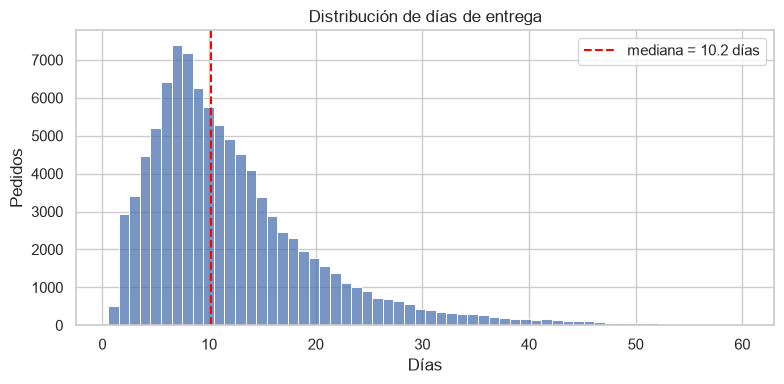

In [5]:
# Marcar si el cliente y el vendedor están en el mismo estado.
entregas['mismo_estado'] = (
    entregas['customer_state'] == entregas['seller_state']
).astype(int)

# Extraer el mes y el día de la semana de la compra.
entregas['mes'] = entregas['order_purchase_timestamp'].dt.month
entregas['dia_semana'] = entregas['order_purchase_timestamp'].dt.day_of_week

# Contar los pedidos de toda la plataforma en la semana de compra.
pedidos_por_semana = orders['order_purchase_timestamp'].dt.to_period('W').value_counts()
entregas['pedidos_semana'] = (
    entregas['order_purchase_timestamp'].dt.to_period('W').map(pedidos_por_semana)
)

# Definir las variables categóricas y numéricas.
cat_cols = ['customer_state', 'seller_state', 'categoria']
num_cols = [
    'mismo_estado',
    'n_items',
    'precio_total',
    'flete_total',
    'peso_total',
    'pedidos_semana',
    'mes',
    'dia_semana',
]

# Quitar nulos y outliers extremos (más de 60 días).
n_inicial = len(entregas)
entregas = entregas.dropna(subset=cat_cols + num_cols)
entregas = entregas[entregas['dias_entrega'].between(0, 60)]
print(
    'Filas eliminadas:',
    n_inicial - len(entregas),
    f'({(n_inicial - len(entregas)) / n_inicial:.1%})',
    '| Filas finales:',
    len(entregas),
)

# Visualizar la distribución del target.
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(entregas['dias_entrega'], bins=60, ax=ax)
ax.axvline(
    entregas['dias_entrega'].median(),
    color='red',
    ls='--',
    label=f"mediana = {entregas['dias_entrega'].median():.1f} días",
)
ax.set(title='Distribución de días de entrega', xlabel='Días', ylabel='Pedidos')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### 1.3 Pipeline y modelos

El `ColumnTransformer` aplica One-Hot a las categóricas (se quedan las 15 más
frecuentes y el resto va a "infrequent") y deja pasar las numéricas sin cambios.
Los árboles **no necesitan escalado**.

| Modelo | Para qué está |
| --- | --- |
| Baseline (media) | El piso mínimo a superar: siempre predice el promedio. |
| Árbol sin límite | A propósito, para *ver* el overfitting. |
| Árbol `max_depth=8` | El mismo árbol, pero regularizado. |
| Random Forest | Muchos árboles que votan: reduce la varianza. |
| Gradient Boosting | Árboles que corrigen el error del anterior (`HistGradientBoostingRegressor`, rápido con ~95k filas). |

Comparamos con **MAE de CV en train**: se interpreta directamente como "días de error".

In [6]:
def pipeline_entregas(modelo):
    # Codificar las categóricas y dejar pasar las numéricas sin cambios.
    preparar = ColumnTransformer(
        [
            (
                'cat',
                OneHotEncoder(
                    handle_unknown='infrequent_if_exist',
                    max_categories=15,
                    sparse_output=False,
                ),
                cat_cols,
            ),
        ],
        remainder='passthrough',
    )

    # Integrar la preparación y el modelo en un único Pipeline.
    return Pipeline([('preparar', preparar), ('modelo', modelo)])


# Separar features y target.
X = entregas[cat_cols + num_cols]
y = entregas['dias_entrega']

# Dividir en train y test.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=.2,
    random_state=RANDOM_STATE,
)

# Definir los modelos a comparar.
modelos_entregas = {
    'Baseline (media)': pipeline_entregas(DummyRegressor(strategy='mean')),
    'Árbol sin límite': pipeline_entregas(
        DecisionTreeRegressor(random_state=RANDOM_STATE)
    ),
    'Árbol max_depth=8': pipeline_entregas(
        DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE)
    ),
    'Random Forest': pipeline_entregas(
        RandomForestRegressor(
            n_estimators=100,
            min_samples_leaf=10,
            max_features=.5,
            random_state=RANDOM_STATE,
        )
    ),
    'Gradient Boosting': pipeline_entregas(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    ),
}

# Comparar los modelos con validación cruzada sobre train.
tabla_entregas = comparar_modelos(
    modelos_entregas,
    X_train,
    y_train,
    scoring='neg_mean_absolute_error',
)
display(tabla_entregas.sort_values('validacion'))

,train,validacion,validacion_std,gap
modelo,,,,
Random Forest,3.814,4.423,0.024,0.609
Gradient Boosting,4.329,4.450,0.032,0.121
Árbol max_depth=8,4.676,4.771,0.035,0.095
Árbol sin límite,0.041,6.097,0.042,6.055
Baseline (media),6.122,6.122,0.051,0.000


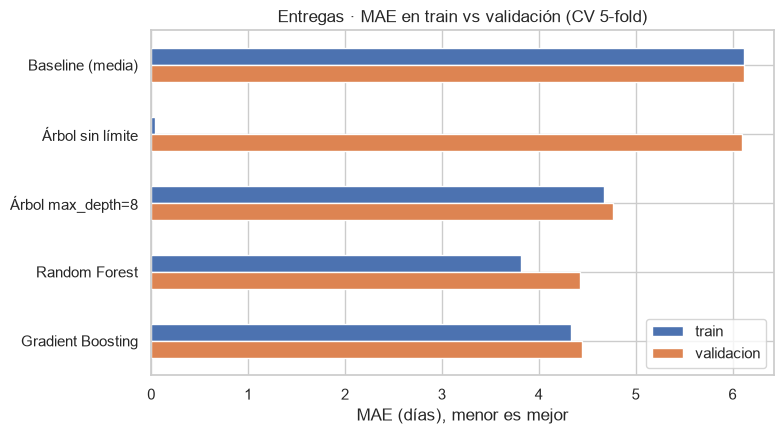

In [7]:
# Visualizar el MAE de train frente al de validación.
graficar_train_vs_validacion(
    tabla_entregas,
    'MAE (días), menor es mejor',
    'Entregas · MAE en train vs validación (CV 5-fold)',
)

### 1.4 Overfitting: curva de profundidad del árbol

Al aumentar `max_depth`, el error de **train** baja siempre. El de **validación**
baja hasta un punto y después sube o se estanca. Ese punto separa el underfitting
(izquierda) del overfitting (derecha).

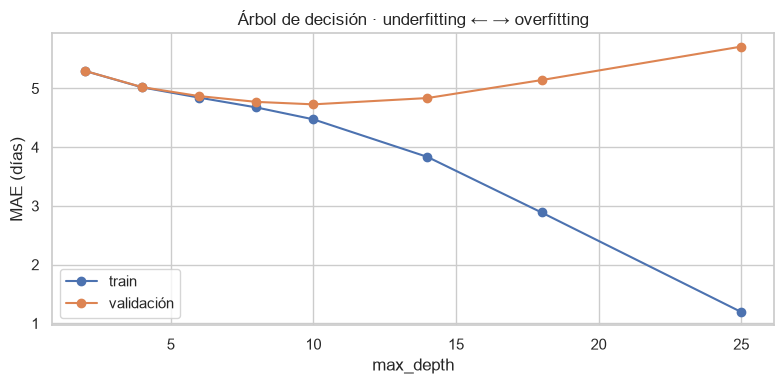

In [8]:
# Calcular el MAE de train y validación para cada profundidad.
profundidades = [2, 4, 6, 8, 10, 14, 18, 25]
train_sc, val_sc = validation_curve(
    pipeline_entregas(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    X_train,
    y_train,
    param_name='modelo__max_depth',
    param_range=profundidades,
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1,
)

# Graficar ambas curvas: sklearn devuelve el error negativo.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profundidades, -train_sc.mean(axis=1), 'o-', label='train')
ax.plot(profundidades, -val_sc.mean(axis=1), 'o-', label='validación')
ax.set(
    title='Árbol de decisión · underfitting ← → overfitting',
    xlabel='max_depth',
    ylabel='MAE (días)',
)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### 1.5 Evaluación final en test

Reentrenamos el mejor modelo (menor MAE de validación) con todo el train y lo
evaluamos **una sola vez** en test. Además lo comparamos con la **estimación que
Olist ya le muestra al cliente** (`order_estimated_delivery_date`).

In [9]:
# Reentrenar el modelo con menor MAE de validación.
mejor_entregas = tabla_entregas['validacion'].idxmin()
modelo_entregas = modelos_entregas[mejor_entregas].fit(X_train, y_train)
pred = modelo_entregas.predict(X_test)

# Evaluar el modelo en test.
mae_entregas = mean_absolute_error(y_test, pred)
rmse_entregas = root_mean_squared_error(y_test, pred)
r2_entregas = r2_score(y_test, pred)

# Calcular el error de la estimación que hoy muestra Olist.
estimacion_olist = (
    entregas.loc[X_test.index, 'order_estimated_delivery_date']
    - entregas.loc[X_test.index, 'order_purchase_timestamp']
).dt.total_seconds() / 86400
mae_olist = mean_absolute_error(y_test, estimacion_olist)

# Mostrar ambos resultados lado a lado.
display(
    pd.DataFrame(
        {
            'MAE (días)': [mae_entregas, mae_olist],
            'RMSE (días)': [
                rmse_entregas,
                root_mean_squared_error(y_test, estimacion_olist),
            ],
            'R²': [r2_entregas, r2_score(y_test, estimacion_olist)],
        },
        index=[mejor_entregas, 'Estimación actual de Olist'],
    )
)

# Resumir cuánto sobreestima Olist la fecha de entrega.
display(
    Markdown(
        f'Mejor modelo: **{mejor_entregas}**, con un error medio de **{mae_entregas:.1f} días**. '
        f'Olist sobreestima en promedio **{(estimacion_olist - y_test).mean():.1f} días**.'
    )
)

,MAE (días),RMSE (días),R²
Random Forest,4.474,6.564,0.403
Estimación actual de Olist,12.649,14.707,-1.997


Mejor modelo: **Random Forest**, con un error medio de **4.5 días**. Olist sobreestima en promedio **11.4 días**.

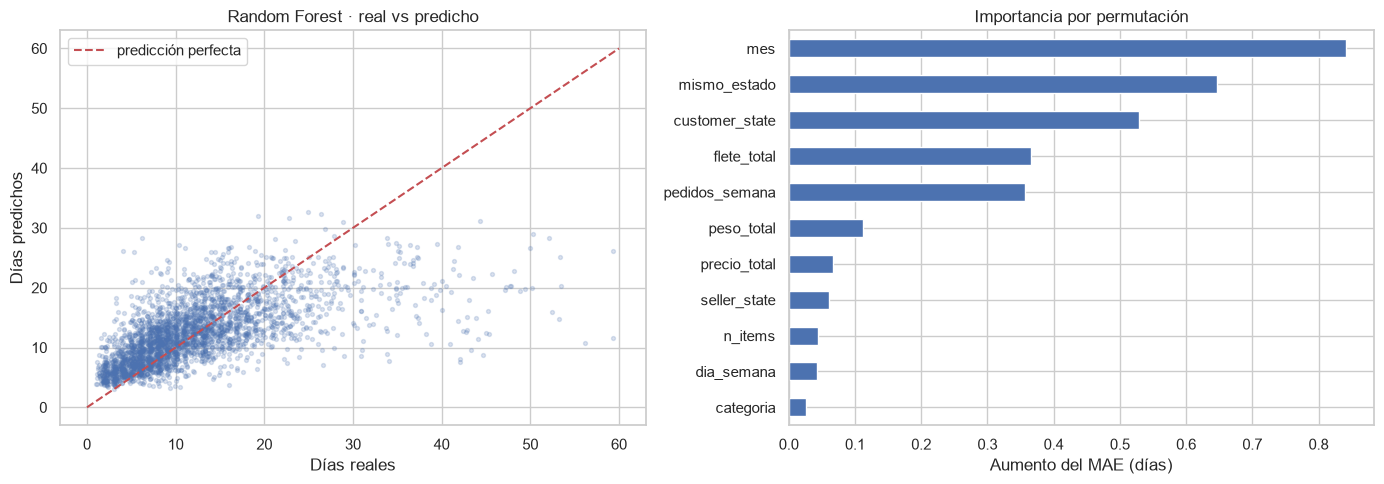

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparar días reales y predichos sobre una muestra del test.
muestra = np.random.default_rng(RANDOM_STATE).choice(
    len(y_test),
    size=min(3000, len(y_test)),
    replace=False,
)
axes[0].scatter(y_test.iloc[muestra], pred[muestra], alpha=.2, s=8)
axes[0].plot([0, 60], [0, 60], 'r--', label='predicción perfecta')
axes[0].set(
    title=f'{mejor_entregas} · real vs predicho',
    xlabel='Días reales',
    ylabel='Días predichos',
)
axes[0].legend()

# Medir cuánto empeora el MAE al desordenar cada variable.
X_imp, y_imp = X_test.iloc[:5000], y_test.iloc[:5000]
imp = permutation_importance(
    modelo_entregas,
    X_imp,
    y_imp,
    scoring='neg_mean_absolute_error',
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
pd.Series(imp.importances_mean, index=X_imp.columns).sort_values().plot.barh(ax=axes[1])
axes[1].set(title='Importancia por permutación', xlabel='Aumento del MAE (días)')

fig.tight_layout()
plt.show()
plt.close(fig)

### 1.6 ¿Qué significan estos resultados para las entregas?

**El árbol sin límite memoriza.** En train se equivoca **0,04 días**; en validación,
**6,10 días**, casi lo mismo que el baseline que siempre predice la media (6,12).
Aprendió cada pedido de memoria y no generaliza. La curva de profundidad lo muestra
paso a paso: hasta `max_depth≈10` train y validación bajan juntos (underfitting
que se corrige); a partir de ahí el error de train sigue cayendo hasta 1,2 días,
mientras el de validación sube hasta 5,7 (overfitting).

**Random Forest gana, pero por poco.** Tiene el menor MAE de validación (**4,42 días**)
y en test se equivoca **4,47 días** de media, con R² de **0,40**. Gradient Boosting
queda prácticamente empatado (4,45) con un gap mucho menor (0,12 contra 0,61). Si
priorizamos estabilidad, Gradient Boosting es una alternativa igual de válida.

**El modelo supera ampliamente a Olist.** La fecha estimada que hoy ve el cliente
falla por **12,65 días** de media y sobreestima la entrega en **11,4 días**: está
inflada a propósito para no incumplir. Su R² negativo (−2,0) indica que es peor que
predecir siempre el promedio. El modelo reduce el error a casi un tercio.

**El modelo subestima las entregas muy largas.** En el gráfico real vs predicho,
los pedidos que tardaron más de 25–30 días se predicen alrededor de 20. Esos retrasos
extremos dependen de factores que no están en los datos (huelgas, extravíos,
problemas del transportista). Para comunicar fechas al cliente convendría sumar
un margen, porque prometer de menos es peor que prometer de más.

**¿Qué pesa más?** El **mes de compra** es la variable más importante: la logística
se satura en temporadas de alta demanda, algo que también refleja `pedidos_semana`.
Le siguen la **ubicación** (`mismo_estado`, `customer_state`) y el **flete**. La
categoría del producto casi no aporta.

---
## 2. 🛍️ Recomendaciones Inteligentes (PCA + K-Means)

> *Si tu recomendador sugiere un bikini a alguien que compró una laptop gamer… tenemos que hablar.*

Agrupamos **productos** parecidos (precio, tamaño, flete, popularidad, valoración y
categoría). Para un producto comprado, recomendamos los más vendidos de su mismo cluster.

¿Por qué productos y no clientes? En Olist casi todos los clientes compran **una sola
vez**, así que no hay historial de cliente para agrupar.

### 2.1 Datos (una fila por producto)

Nos quedamos con los productos con al menos 3 ventas para reducir el ruido.

In [11]:
# Resumir las ventas, el precio y el flete de cada producto.
ventas = items.groupby('product_id').agg(
    n_ventas=('order_id', 'count'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
).reset_index()

# Calcular la valoración media de cada producto a partir de sus pedidos.
score_producto = (
    items[['order_id', 'product_id']]
    .drop_duplicates()
    .merge(reviews[['order_id', 'review_score']], on='order_id')
    .groupby('product_id')['review_score']
    .mean()
    .rename('score_medio')
    .reset_index()
)

# Definir las variables numéricas del producto.
num_prod = [
    'precio_medio',
    'flete_medio',
    'n_ventas',
    'score_medio',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm',
    'product_photos_qty',
]

# Unir todo y quedarse con los productos con al menos 3 ventas.
prod = (
    products
    .merge(ventas, on='product_id')
    .merge(score_producto, on='product_id', how='left')
)
prod = prod[prod['n_ventas'] >= 3].dropna(subset=num_prod).reset_index(drop=True)
print('Productos con al menos 3 ventas:', len(prod))
display(prod[num_prod].describe().T)

Productos con al menos 3 ventas: 8889


,count,mean,std,min,25%,50%,75%,max
precio_medio,8889.000,120.368,178.238,0.850,37.900,70.500,135.000,3133.323
flete_medio,8889.000,19.927,13.841,0.030,13.938,16.654,21.082,308.337
n_ventas,8889.000,9.208,19.139,3.000,3.000,5.000,8.000,527.000
score_medio,8889.000,4.048,0.809,1.000,3.667,4.200,4.667,5.000
product_weight_g,8889.000,2042.373,3711.894,0.000,300.000,650.000,1750.000,40425.000
product_length_cm,8889.000,30.310,16.440,7.000,18.000,25.000,38.000,105.000
product_height_cm,8889.000,16.704,13.773,2.000,8.000,13.000,20.000,105.000
product_width_cm,8889.000,22.816,11.687,8.000,15.000,20.000,30.000,118.000
product_photos_qty,8889.000,2.226,1.723,1.000,1.000,2.000,3.000,15.000


### 2.2 Pipeline de preprocesamiento + PCA

Precios, pesos y ventas están **muy sesgados**: unos pocos productos son enormes o
carísimos. Aplicamos `log1p` y después `StandardScaler`. Sin el log, K-Means armaría
clusters solo para los outliers. La categoría entra como One-Hot (las 15 más frecuentes).

Para **PCA** elegimos el número de componentes que explica alrededor del **90 %** de
la varianza.

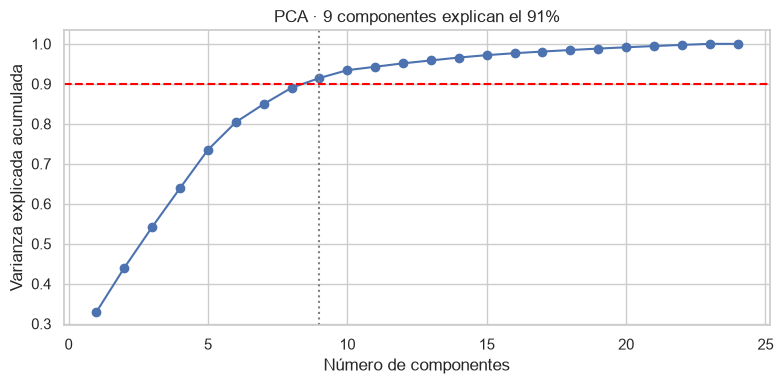

Dimensiones: 24 originales → 9 con PCA


In [12]:
# Aplicar log y escalado a las numéricas; One-Hot a la categoría.
prep_prod = ColumnTransformer(
    [
        (
            'num',
            make_pipeline(
                FunctionTransformer(np.log1p),
                StandardScaler(),
            ),
            num_prod,
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='infrequent_if_exist',
                max_categories=15,
                sparse_output=False,
            ),
            ['categoria'],
        ),
    ]
)
X_prod = prep_prod.fit_transform(prod)

# Buscar cuántas componentes explican el 90 % de la varianza.
pca_full = PCA().fit(X_prod)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(var_acum >= .90) + 1)

# Graficar la varianza explicada acumulada.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(var_acum) + 1), var_acum, 'o-')
ax.axhline(.90, color='red', ls='--')
ax.axvline(n_comp, color='gray', ls=':')
ax.set(
    title=f'PCA · {n_comp} componentes explican el {var_acum[n_comp - 1]:.0%}',
    xlabel='Número de componentes',
    ylabel='Varianza explicada acumulada',
)
fig.tight_layout()
plt.show()
plt.close(fig)

print('Dimensiones:', X_prod.shape[1], 'originales →', n_comp, 'con PCA')

### 2.3 Comparación: ¿cuántos clusters? ¿Con o sin PCA?

En no supervisado no hay "accuracy". Comparamos con dos métricas:

| Métrica | Qué responde |
| --- | --- |
| Inercia (método del codo) | ¿Cuánto se compactan los clusters? Baja siempre; buscamos dónde deja de bajar rápido. |
| Silhouette (−1 a 1) | ¿Qué tan separados y compactos quedan? Más alto es mejor. |

Y comparamos **dos "modelos"**: K-Means sobre los datos escalados originales y
K-Means sobre las componentes PCA.

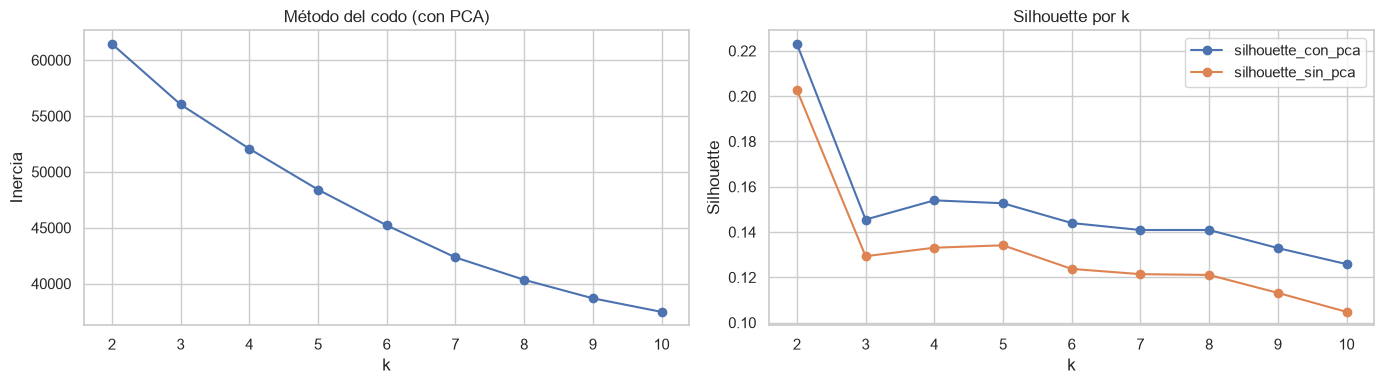

k elegido: 4


,inercia_pca,silhouette_con_pca,silhouette_sin_pca
k,,,
2,61456.117,0.223,0.203
3,56031.757,0.145,0.129
4,52072.526,0.154,0.133
5,48412.857,0.153,0.134
6,45218.642,0.144,0.124
7,42346.641,0.141,0.121
8,40342.239,0.141,0.121
9,38685.375,0.133,0.113
10,37471.706,0.126,0.105


In [13]:
# Proyectar los productos sobre las componentes elegidas.
X_pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit_transform(X_prod)

# Probar K-Means de 2 a 10 clusters, con y sin PCA.
filas = []

for k in range(2, 11):
    km_pca = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    km_orig = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_prod)
    filas.append(
        {
            'k': k,
            'inercia_pca': km_pca.inertia_,
            'silhouette_con_pca': silhouette_score(
                X_pca,
                km_pca.labels_,
                sample_size=5000,
                random_state=RANDOM_STATE,
            ),
            'silhouette_sin_pca': silhouette_score(
                X_prod,
                km_orig.labels_,
                sample_size=5000,
                random_state=RANDOM_STATE,
            ),
        }
    )

resultados_k = pd.DataFrame(filas).set_index('k')

# Graficar el codo y el silhouette.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
resultados_k['inercia_pca'].plot(ax=axes[0], marker='o')
axes[0].set(title='Método del codo (con PCA)', ylabel='Inercia')
resultados_k[['silhouette_con_pca', 'silhouette_sin_pca']].plot(ax=axes[1], marker='o')
axes[1].set(title='Silhouette por k', ylabel='Silhouette')
fig.tight_layout()
plt.show()
plt.close(fig)

# Elegir k desde 3: k=2 suele ganar en silhouette pero es demasiado grueso para recomendar.
# Si el codo sugiere otro k, se puede fijar a mano.
K = int(resultados_k.loc[3:, 'silhouette_con_pca'].idxmax())
print('k elegido:', K)
display(resultados_k)

### 2.4 Overfitting / estabilidad

En clustering, "generalizar" significa que los clusters **sirven también para
productos nuevos**. Entrenamos el pipeline completo (`preparar → PCA → KMeans`) con
el 80 % de los productos, asignamos cluster al 20 % restante y comparamos:

- El silhouette en train y en test, que deberían ser parecidos.
- La proporción de productos por cluster, que debería mantenerse.

In [14]:
def pipeline_recomendador():
    # Encadenar preparación, PCA y K-Means en un único Pipeline.
    return Pipeline(
        [
            ('preparar', clone(prep_prod)),
            ('pca', PCA(n_components=n_comp, random_state=RANDOM_STATE)),
            ('kmeans', KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)),
        ]
    )


# Entrenar con el 80 % de los productos.
prod_train, prod_test = train_test_split(
    prod,
    test_size=.2,
    random_state=RANDOM_STATE,
)
recomendador = pipeline_recomendador().fit(prod_train)

# Transformar ambos conjuntos y asignar clusters al test.
Z_train = recomendador[:-1].transform(prod_train)
Z_test = recomendador[:-1].transform(prod_test)
etiquetas_train = recomendador['kmeans'].labels_
etiquetas_test = recomendador.predict(prod_test)

# Comparar el silhouette de train y test.
sil_train = silhouette_score(
    Z_train,
    etiquetas_train,
    sample_size=5000,
    random_state=RANDOM_STATE,
)
sil_test = silhouette_score(
    Z_test,
    etiquetas_test,
    sample_size=5000,
    random_state=RANDOM_STATE,
)
print(
    f'Silhouette train: {sil_train:.3f}',
    f'| test: {sil_test:.3f}',
    f'| gap: {abs(sil_train - sil_test):.3f}',
)

# Comparar la proporción de productos por cluster.
display(
    pd.DataFrame(
        {
            '% train': pd.Series(etiquetas_train).value_counts(normalize=True),
            '% test': pd.Series(etiquetas_test).value_counts(normalize=True),
        }
    ).sort_index()
)

Silhouette train: 0.154 | test: 0.151 | gap: 0.003


,% train,% test
0,0.415,0.406
1,0.068,0.074
2,0.385,0.385
3,0.133,0.135


### 2.5 Modelo final, visualización y perfil de clusters

Reentrenamos con todos los productos y describimos cada cluster con sus medianas y
su categoría dominante.

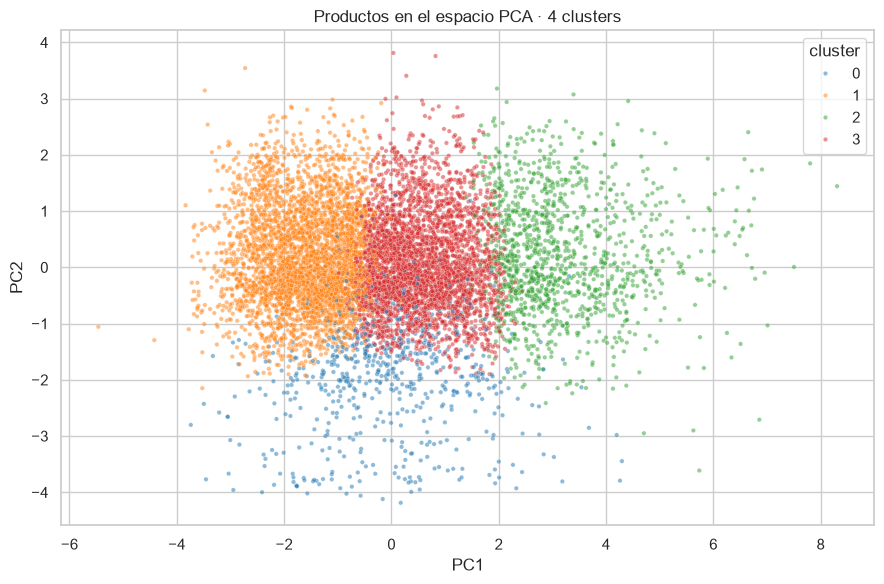

,n_productos,categoria_top,pct_categoria_top,precio_mediano,flete_mediano,peso_mediano_g,ventas_medianas,score_medio
cluster,,,,,,,,
0,648,bed_bath_table,0.170,62.995,16.320,700.000,4.000,2.158
1,3650,health_beauty,0.107,39.900,14.472,250.000,5.000,4.217
2,1219,housewares,0.102,177.225,32.967,7350.000,5.000,4.010
3,3372,bed_bath_table,0.156,89.938,17.555,1150.000,5.000,4.243


In [15]:
# Reentrenar con todos los productos y guardar el cluster de cada uno.
recomendador = pipeline_recomendador().fit(prod)
prod['cluster'] = recomendador['kmeans'].labels_
Z = recomendador[:-1].transform(prod)

# Visualizar los productos sobre las dos primeras componentes.
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    x=Z[:, 0],
    y=Z[:, 1],
    hue=prod['cluster'],
    palette='tab10',
    s=10,
    alpha=.5,
    ax=ax,
)
ax.set(
    title=f'Productos en el espacio PCA · {K} clusters',
    xlabel='PC1',
    ylabel='PC2',
)
fig.tight_layout()
plt.show()
plt.close(fig)

# Describir cada cluster.
perfil = prod.groupby('cluster').agg(
    n_productos=('product_id', 'count'),
    categoria_top=('categoria', lambda s: s.value_counts().index[0]),
    pct_categoria_top=('categoria', lambda s: s.value_counts(normalize=True).iloc[0]),
    precio_mediano=('precio_medio', 'median'),
    flete_mediano=('flete_medio', 'median'),
    peso_mediano_g=('product_weight_g', 'median'),
    ventas_medianas=('n_ventas', 'median'),
    score_medio=('score_medio', 'mean'),
)
display(perfil)

### 2.6 El recomendador

Dado un producto comprado, devuelve los `n` productos **más vendidos de su mismo cluster**.

In [16]:
def recomendar(product_id, n=5):
    # Buscar el cluster del producto comprado.
    producto = prod.loc[prod['product_id'] == product_id].iloc[0]

    # Devolver los más vendidos de ese cluster, sin repetir el producto.
    candidatos = prod[
        (prod['cluster'] == producto['cluster'])
        & (prod['product_id'] != product_id)
    ]
    return candidatos.nlargest(n, 'n_ventas')[
        ['product_id', 'categoria', 'precio_medio', 'n_ventas', 'score_medio']
    ]


# Mostrar un ejemplo de recomendación para cada uno de los 3 primeros clusters.
for c in range(min(3, K)):
    ejemplo = prod[prod['cluster'] == c].sample(1, random_state=RANDOM_STATE).iloc[0]
    display(
        Markdown(
            f"🛒 Compró: **{ejemplo['categoria']}** "
            f"(precio {ejemplo['precio_medio']:.0f} R$) → cluster {c}"
        )
    )
    display(recomendar(ejemplo['product_id']))

🛒 Compró: **furniture_decor** (precio 84 R$) → cluster 0

,product_id,categoria,precio_medio,n_ventas,score_medio
7022,89b121bee266dcd25688a1ba72eefb61,computers_accessories,79.900,68,2.279
1313,cd46a885543f0e169a49f1eb25c04e43,computers_accessories,99.990,30,1.607
7101,ad4b5def91ac7c575dbdf65b5be311f4,computers_accessories,21.398,22,1.667
6695,6d2fde7d12bb6ff367dbda120ba8828e,computers_accessories,21.972,18,1.667
3511,e6b314a2236c162ede1a879f1075430f,computers_accessories,20.430,16,1.667


🛒 Compró: **watches_gifts** (precio 169 R$) → cluster 1

,product_id,categoria,precio_medio,n_ventas,score_medio
200,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,116.667,323,4.234
455,154e7e31ebfa092203795c972e5804a6,health_beauty,22.510,281,4.318
1566,2b4609f8948be18874494203496bc318,health_beauty,87.374,260,4.071
821,7c1bd920dbdf22470b68bde975dd3ccf,health_beauty,60.029,231,3.878
5709,e53e557d5a159f5aa2c5e995dfdf244b,computers_accessories,84.367,183,3.544


🛒 Compró: **home_construction** (precio 222 R$) → cluster 2

,product_id,categoria,precio_medio,n_ventas,score_medio
2202,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,137.652,343,4.234
7899,f1c7f353075ce59d8a6f3cf58f419c9c,bed_bath_table,194.788,154,4.372
8496,c4baedd846ed09b85f78a781b522f126,garden_tools,100.598,149,4.266
8310,8c591ab0ca519558779df02023177f44,garden_tools,102.781,141,4.132
6643,52c80cedd4e90108bf4fa6a206ef6b03,garden_tools,173.691,118,4.158


### 2.7 ¿Qué significan estos resultados para las recomendaciones?

**PCA ayuda.** Reduce de 24 a **9 dimensiones** conservando el 90 % de la varianza,
y para **todos** los k el silhouette con PCA es mayor que sin PCA (con k=4: 0,154
contra 0,133). Quitar dimensiones redundantes (largo, alto, ancho y peso están muy
correlacionados) limpia ruido.

**Elegimos k=4.** k=2 tiene el mejor silhouette (0,22), pero partir el catálogo en dos
no sirve para recomendar. Desde k=3, el máximo está en **k=4** (0,154).

**Los clusters son estables, pero se solapan.** El silhouette es casi igual en train
y test (0,154 contra 0,151) y la proporción de productos por cluster se mantiene:
los clusters **generalizan** a productos nuevos. Sin embargo, un silhouette de 0,15
es bajo: los grupos existen, pero tienen bordes difusos. Es esperable con productos
reales, que varían de forma continua.

**Cuatro perfiles claros:**

| Cluster | Productos | Perfil |
| --- | --- | --- |
| 0 | 648 | **Mal valorados**: nota media 2,2, precio y peso medios. |
| 1 | 3.650 | **Pequeños y baratos**: 250 g y 40 R$ de mediana (belleza, salud). |
| 2 | 1.219 | **Voluminosos y caros**: 7,4 kg, 177 R$ y el flete más alto (33 R$). |
| 3 | 3.372 | **Estándar bien valorados**: 1,2 kg, 90 R$, nota 4,2 (cama, mesa y baño). |

**El recomendador tiene un problema que hay que corregir.** Como la valoración es
una variable del clustering, los productos mal valorados forman su propio cluster.
Quien compra un producto del cluster 0 recibe como recomendación... más productos
mal valorados (en el ejemplo, notas entre 1,6 y 2,3). La corrección es simple:
filtrar las recomendaciones por `score_medio` alto, o sacar la valoración del
clustering y usarla solo para ordenar.

**Límite.** Las categorías se mezclan dentro de cada cluster (la dominante no supera
el 17 %): el modelo agrupa por precio, tamaño y valoración, no por tipo de producto.
Además, sugiere productos **parecidos**, no **complementarios** (cafetera → café).
Para eso haría falta analizar qué se compra junto, algo raro en Olist porque casi
todos los pedidos tienen un solo ítem.

---
## 3. 🧠 Análisis de Sentimientos

> *"Cinco estrellas, pero no volvería a comprar."*

Clasificamos una reseña como **positiva** o **negativa** a partir del texto.

**Etiqueta:** a partir de `review_score`: 1–2 → negativo (0), 4–5 → positivo (1).
El **3 se descarta** por ambiguo.

### 3.1 Datos

Reseñas totales: 99224 | con texto: 40977 (41%)


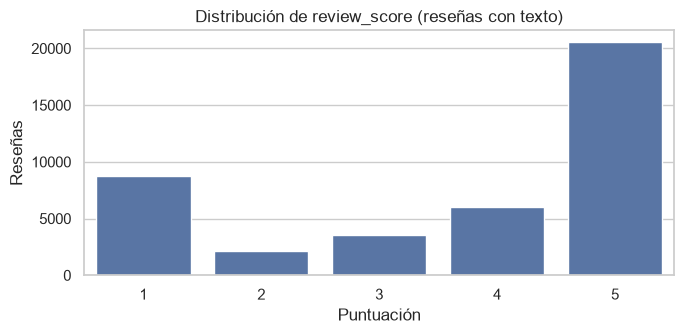

,proporción
sentimiento,
positivo,0.709
negativo,0.291


In [17]:
# Quedarse con las reseñas que tienen texto.
resenas = reviews.dropna(subset=['review_comment_message']).copy()
print(
    'Reseñas totales:',
    len(reviews),
    '| con texto:',
    len(resenas),
    f'({len(resenas) / len(reviews):.0%})',
)

# Visualizar la distribución de las puntuaciones.
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.countplot(x=resenas['review_score'], ax=ax)
ax.set(
    title='Distribución de review_score (reseñas con texto)',
    xlabel='Puntuación',
    ylabel='Reseñas',
)
fig.tight_layout()
plt.show()
plt.close(fig)

# Descartar el 3 y codificar el sentimiento como 0 y 1.
resenas = resenas[resenas['review_score'] != 3]
resenas['sentimiento'] = (resenas['review_score'] >= 4).astype(int)

# Revisar la proporción de cada clase.
display(
    resenas['sentimiento']
    .value_counts(normalize=True)
    .rename({1: 'positivo', 0: 'negativo'})
    .to_frame('proporción')
)

### 3.2 Limpieza del texto

Limpieza mínima: minúsculas, sin tildes y solo letras. Las stopwords en portugués van
en una lista corta escrita a mano.

⚠️ **No** quitamos *não*, *sem*, *nem*, *muito* ni *mais*. Son palabras vacías en
otros contextos, pero aquí **cargan el sentimiento** ("não recebi", "sem problemas").

In [18]:
def limpiar(texto):
    # Pasar a minúsculas y quitar las tildes.
    texto = unicodedata.normalize('NFKD', texto.lower()).encode('ascii', 'ignore').decode()

    # Dejar solo letras y espacios simples.
    texto = re.sub(r'[^a-z\s]', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()


# Definir las stopwords en portugués, sin tildes y sin las que cargan sentimiento.
STOPWORDS_PT = """
a o as os um uma uns umas de do da dos das em no na nos nas ao aos pelo pela pelos pelas
por para com e ou que se como mas eu ele ela eles elas voce voces me te lhe nos vos lhes
meu minha meus minhas seu sua seus suas dele dela deles delas esse essa esses essas este
esta estes estas isso isto aquele aquela aquilo ja tambem so ate entre depois quando qual
quem num numa foi ser sao era estou esta tem ter
""".split()

# Limpiar todas las reseñas.
resenas['texto'] = resenas['review_comment_message'].astype(str).map(limpiar)
display(resenas[['review_comment_message', 'texto', 'sentimiento']].head())

,review_comment_message,texto,sentimiento
3,Recebi bem antes do prazo estipulado.,recebi bem antes do prazo estipulado,1
4,Parabéns lojas lannister adorei comprar pela I...,parabens lojas lannister adorei comprar pela i...,1
9,aparelho eficiente. no site a marca do aparelh...,aparelho eficiente no site a marca do aparelho...,1
12,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",mas um pouco travando pelo valor ta boa,1
15,"Vendedor confiável, produto ok e entrega antes...",vendedor confiavel produto ok e entrega antes ...,1


### 3.3 Pipeline y modelos

`TfidfVectorizer` (palabras sueltas y pares de palabras, mínimo 5 apariciones) →
clasificador.

| Modelo | Idea |
| --- | --- |
| Naive Bayes | El optimista probabilístico: asume que las palabras son independientes. Muy rápido y clásico en texto. |
| SVM lineal | El ninja: busca la frontera que mejor separa las clases en el espacio TF-IDF. |
| Regresión logística | Baseline lineal de referencia, interpretable. |

**Métrica principal: F1 macro**, porque las clases están desbalanceadas. La accuracy
engañaría: un modelo que siempre dice la clase mayoritaria tendría una accuracy alta.

In [19]:
def pipeline_texto(modelo):
    # Vectorizar con TF-IDF y clasificar en un único Pipeline.
    return Pipeline(
        [
            (
                'tfidf',
                TfidfVectorizer(
                    stop_words=STOPWORDS_PT,
                    ngram_range=(1, 2),
                    min_df=5,
                    sublinear_tf=True,
                ),
            ),
            ('modelo', modelo),
        ]
    )


# Separar texto y etiqueta.
Xt = resenas['texto']
yt = resenas['sentimiento']

# Dividir en train y test conservando la proporción de clases.
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    Xt,
    yt,
    test_size=.2,
    stratify=yt,
    random_state=RANDOM_STATE,
)

# Definir los modelos a comparar.
modelos_texto = {
    'Naive Bayes': pipeline_texto(MultinomialNB()),
    'SVM lineal': pipeline_texto(
        LinearSVC(C=1, class_weight='balanced', random_state=RANDOM_STATE)
    ),
    'Regresión logística': pipeline_texto(
        LogisticRegression(max_iter=1000, class_weight='balanced')
    ),
}

# Comparar los modelos con validación cruzada sobre train.
tabla_texto = comparar_modelos(modelos_texto, Xt_train, yt_train, scoring='f1_macro')
display(tabla_texto.sort_values('validacion', ascending=False))

,train,validacion,validacion_std,gap
modelo,,,,
Regresión logística,0.933,0.917,0.003,0.016
Naive Bayes,0.925,0.914,0.003,0.011
SVM lineal,0.959,0.914,0.005,0.045


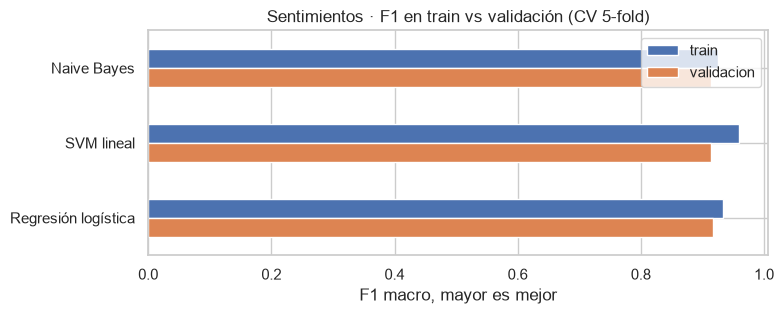

In [20]:
# Visualizar el F1 de train frente al de validación.
graficar_train_vs_validacion(
    tabla_texto,
    'F1 macro, mayor es mejor',
    'Sentimientos · F1 en train vs validación (CV 5-fold)',
)

### 3.4 Overfitting: el parámetro `C` del SVM

`C` controla cuánto se "ajusta" el SVM a los datos de entrenamiento:

- **C chico:** frontera simple, posible underfitting.
- **C grande:** frontera que se dobla para acertar cada ejemplo de train, posible overfitting.

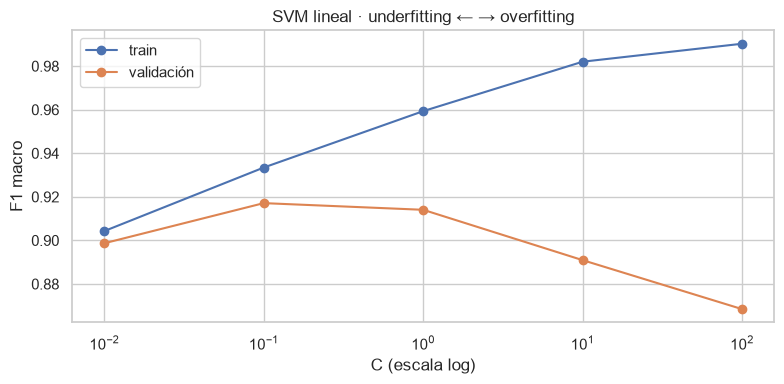

In [21]:
# Calcular el F1 de train y validación para cada valor de C.
valores_C = [.01, .1, 1, 10, 100]
train_sc, val_sc = validation_curve(
    pipeline_texto(
        LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE)
    ),
    Xt_train,
    yt_train,
    param_name='modelo__C',
    param_range=valores_C,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

# Graficar ambas curvas en escala logarítmica.
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(valores_C, train_sc.mean(axis=1), 'o-', label='train')
ax.semilogx(valores_C, val_sc.mean(axis=1), 'o-', label='validación')
ax.set(
    title='SVM lineal · underfitting ← → overfitting',
    xlabel='C (escala log)',
    ylabel='F1 macro',
)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### 3.5 Evaluación final en test

| Métrica | Qué responde |
| --- | --- |
| Precision | De las reseñas que marqué como negativas, ¿qué fracción lo era? |
| Recall | De las reseñas negativas reales, ¿qué fracción detecté? |
| F1 | ¿Cómo se combinan precision y recall? |

La matriz usa filas reales y columnas predichas, normalizada por fila.

Mejor modelo: Regresión logística | F1 macro test: 0.914

              precision    recall  f1-score   support

    negativo       0.83      0.94      0.88      2178
    positivo       0.98      0.92      0.95      5306

    accuracy                           0.93      7484
   macro avg       0.90      0.93      0.91      7484
weighted avg       0.93      0.93      0.93      7484



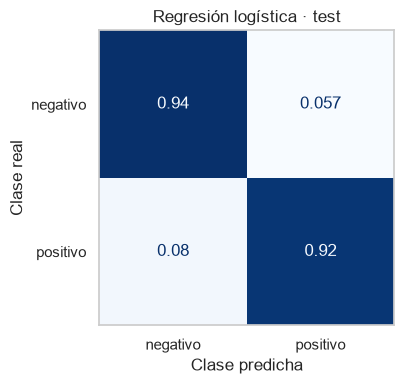

In [22]:
# Reentrenar el modelo con mayor F1 de validación.
mejor_texto = tabla_texto['validacion'].idxmax()
modelo_texto = modelos_texto[mejor_texto].fit(Xt_train, yt_train)
pred_t = modelo_texto.predict(Xt_test)
f1_texto = f1_score(yt_test, pred_t, average='macro')

# Evaluar el modelo en test.
print('Mejor modelo:', mejor_texto, f'| F1 macro test: {f1_texto:.3f}\n')
print(classification_report(yt_test, pred_t, target_names=['negativo', 'positivo']))

# Visualizar los aciertos y errores mediante la matriz de confusión.
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    yt_test,
    pred_t,
    display_labels=['negativo', 'positivo'],
    normalize='true',
    cmap='Blues',
    colorbar=False,
    ax=ax,
)
ax.set(
    title=f'{mejor_texto} · test',
    xlabel='Clase predicha',
    ylabel='Clase real',
)
ax.grid(False)
fig.tight_layout()
plt.show()
plt.close(fig)

### 3.6 Patrones recurrentes: ¿qué dicen los clientes?

Los coeficientes del SVM lineal indican qué términos empujan una reseña hacia
**negativo** o **positivo**. Detrás de cada término hay una señal estratégica.

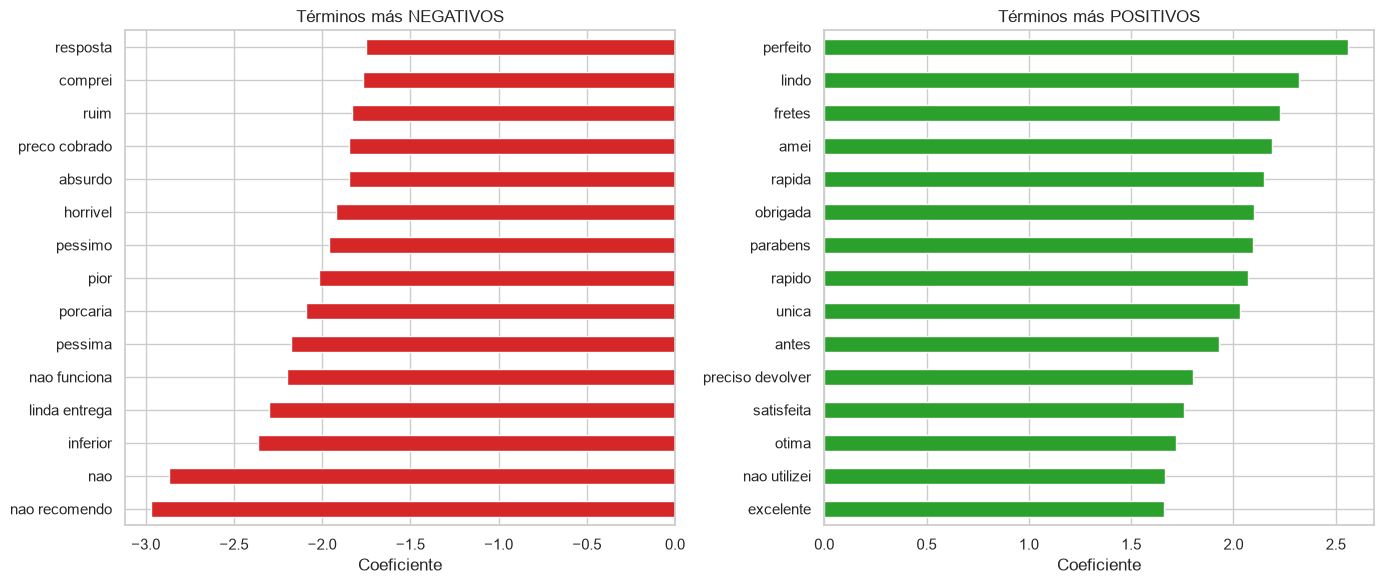

,% que menciona la entrega
sentimiento,
negativas,0.647
positivas,0.490


In [23]:
# Entrenar el SVM lineal y ordenar los términos según su coeficiente.
svm = modelos_texto['SVM lineal'].fit(Xt_train, yt_train)
coefs = pd.Series(
    svm['modelo'].coef_[0],
    index=svm['tfidf'].get_feature_names_out(),
).sort_values()

# Graficar los 15 términos más negativos y los 15 más positivos.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
coefs.head(15).plot.barh(ax=axes[0], color='tab:red')
axes[0].set(title='Términos más NEGATIVOS', xlabel='Coeficiente')
coefs.tail(15).plot.barh(ax=axes[1], color='tab:green')
axes[1].set(title='Términos más POSITIVOS', xlabel='Coeficiente')
fig.tight_layout()
plt.show()
plt.close(fig)

# Conectar con la Misión 1: medir cuántas reseñas hablan de la entrega.
menciona_entrega = resenas['texto'].str.contains(r'entreg|prazo|atras|receb|cheg')
display(
    menciona_entrega
    .groupby(resenas['sentimiento'])
    .mean()
    .rename({0: 'negativas', 1: 'positivas'})
    .to_frame('% que menciona la entrega')
)

### 3.7 ¿Qué significan estos resultados para las reseñas?

**Los tres modelos empatan.** Solo el **41 %** de las reseñas tiene texto; de esas,
el 71 % es positiva. En validación, la regresión logística obtiene **0,917** de F1
macro, y Naive Bayes y el SVM **0,914**. Las diferencias están dentro de la
variación entre folds. Lo que los separa es el gap: Naive Bayes (0,011) y la
logística (0,016) generalizan mejor que el SVM (0,045).

**El SVM sobreajusta con C alto.** La curva de `C` muestra el patrón clásico: con
C=0,01 train y validación están cerca (0,90); el mejor punto de validación está en
**C=0,1** (0,917); con C=100 el train llega a 0,99 pero la validación cae a 0,87. Con
C=1 (el valor por defecto) el SVM ya está algo sobreajustado.

**En test, la logística detecta el 94 % de las reseñas negativas.** Su F1 macro es
**0,914**. Para la clase negativa, el recall es **0,94** y la precision **0,83**: de
cada 100 reseñas que marca como negativas, 17 eran positivas. Para monitorear
quejas es un buen equilibrio: casi no se escapan reseñas negativas.

**¿Qué dicen los clientes?** Los términos más negativos hablan sobre todo del
**producto**: *"nao recomendo"*, *"nao funciona"*, *"inferior"*, *"porcaria"*,
*"preco cobrado"*. Los positivos combinan producto y **rapidez**: *"perfeito"*,
*"amei"*, *"rapida"*, *"rapido"*, *"antes"* (llegó antes de lo previsto). Algunos
términos raros (*"linda entrega"* como negativo, *"preciso devolver"* como positivo)
son bigramas poco frecuentes que el SVM memorizó: otra señal de su sobreajuste.

**La entrega aparece en todas las reseñas.** El **65 %** de las negativas menciona la
entrega, frente al **49 %** de las positivas. Es el tema más comentado en ambos
casos, pero pesa más en las quejas. Cruzando con la Misión 1, avisar antes de un
retraso previsto puede convertir parte de esas quejas en reseñas neutras.

---
## 4. Conclusiones y límites

In [24]:
# Resumir el mejor modelo de cada misión.
resumen = pd.DataFrame(
    [
        {
            'Misión': '🚚 Entregas',
            'Mejor modelo': mejor_entregas,
            'Métrica (test)': f'MAE = {mae_entregas:.2f} días | R² = {r2_entregas:.2f}',
            'Referencia': f'Estimación Olist: MAE = {mae_olist:.2f} días',
        },
        {
            'Misión': '🛍️ Recomendaciones',
            'Mejor modelo': f'PCA({n_comp}) + K-Means (k={K})',
            'Métrica (test)': f'Silhouette = {sil_test:.3f}',
            'Referencia': f'Silhouette train = {sil_train:.3f}',
        },
        {
            'Misión': '🧠 Sentimientos',
            'Mejor modelo': mejor_texto,
            'Métrica (test)': f'F1 macro = {f1_texto:.3f}',
            'Referencia': f"Naive Bayes (val.) = {tabla_texto.loc['Naive Bayes', 'validacion']:.3f}",
        },
    ]
).set_index('Misión')
display(resumen)

,Mejor modelo,Métrica (test),Referencia
Misión,,,
🚚 Entregas,Random Forest,MAE = 4.47 días | R² = 0.40,Estimación Olist: MAE = 12.65 días
🛍️ Recomendaciones,PCA(9) + K-Means (k=4),Silhouette = 0.151,Silhouette train = 0.154
🧠 Sentimientos,Regresión logística,F1 macro = 0.914,Naive Bayes (val.) = 0.914


**No hay modelo "más cool": hay modelo más adecuado.** En entregas, los ensambles
reducen el error del baseline de 6,1 a 4,4 días. En texto, el modelo más simple
(Naive Bayes) empata con los más complejos, así que el criterio de desempate es el
gap. En clustering, la elección del k combina silhouette y utilidad de negocio.

**Train contra validación fue la herramienta clave.** Detectó el overfitting (el árbol
sin límite: 0,04 contra 6,10 días; el SVM con C=100: 0,99 contra 0,87 de F1) y el
underfitting (el baseline, los árboles de profundidad 2–4). Los **pipelines**
garantizan que el preprocesamiento se aprenda solo con train dentro de cada fold,
sin fugas de información.

**Recomendaciones para Olist**

1. **Entregas:** reemplazar la estimación actual, que falla por 12,6 días de media,
   por la del modelo (4,5 días), sumando un margen para no subestimar los retrasos
   largos. Reforzar la logística en los meses de alta demanda.
2. **Reseñas:** clasificar de forma automática las reseñas negativas (se detecta el
   94 %) y atacar sus dos causas: calidad de producto y entrega, presente en el 65 %
   de las quejas.
3. **Recomendaciones:** usar los clusters para "productos similares" en la ficha de
   producto, **filtrando los mal valorados** para no recomendar el cluster de nota 2,2.
4. **Las tres misiones se conectan:** predecir bien la entrega → menos sorpresas →
   mejores reseñas → clientes que vuelven.

**Límites**

- La selección de modelos usa CV en train; después de observar test no reajustamos
  los modelos. Las cifras corresponden a esta ejecución, con semilla 42 y los CSV locales.
- Es un análisis retrospectivo: no prueba que actuar sobre estas predicciones cambie
  el comportamiento de los clientes.